(sec-3)=
# 3. Revisión del estado del arte y extracción de los tres modelos base

En esta sección se documenta la búsqueda de literatura, se identifican los modelos de Deep Learning más básicos que los estudios emplean como referencia al detectar intrusiones en redes de drones y se justifica la elección de los tres modelos base. Su resultado central es la tabla de frecuencia, de la cual salen esos tres modelos, y esto es primordial porque el baseline de todo el proyecto depende de esa elección.

(sec-3-1)=
## 3.1 Estrategia de búsqueda

**Cadenas de búsqueda.** Se usaron tres cadenas booleanas sobre título y resumen, o el campo más cercano de cada base, para publicaciones de 2019 a 2026, es decir, los últimos ocho años. La primera es general; la segunda se concentra en los ataques de red de este proyecto, y la tercera busca el uso directo del conjunto de datos.

| Cadena | Consulta |
|---|---|
| C1 | (drone OR UAV OR "unmanned aerial" OR FANET) AND ("intrusion detection" OR "attack detection") AND ("deep learning" OR "neural network" OR CNN OR LSTM OR MLP) |
| C2 | (drone OR UAV OR "unmanned aerial" OR FANET) AND (swarm OR "ad hoc" OR "network traffic") AND (blackhole OR wormhole OR sybil OR flooding OR cyberattack) AND ("deep learning" OR "neural network" OR CNN OR LSTM OR MLP) |
| C3 | UAVIDS OR "UAVIDS-2025" |

**Palabras clave, sinónimos y variantes.** Cada cadena combina conceptos con AND y, dentro de cada concepto, sinónimos y variantes terminológicas con OR. Las comillas buscan la frase exacta, y los términos van en inglés porque es el idioma en que las bases indexan títulos y resúmenes.

| Concepto | Palabras clave, sinónimos y variantes | Cadenas |
|---|---|---|
| Plataforma | drone, UAV, "unmanned aerial", FANET | C1 y C2 |
| Tarea | "intrusion detection", "attack detection" | C1 |
| Contexto de red | swarm, "ad hoc", "network traffic" | C2 |
| Ataques del conjunto de datos | blackhole, wormhole, sybil, flooding, cyberattack | C2 |
| Método | "deep learning", "neural network", CNN, LSTM, MLP | C1 y C2 |
| Conjunto de datos | UAVIDS, "UAVIDS-2025" | C3 |

**Cadena exacta por base.** La cadena booleana es la misma en todas las bases, y cambian el campo y el filtro de años, porque cada base los define a su manera. En la tabla, *S* representa la cadena C1, C2 o C3 tal como aparece arriba.

| Base | Cadena ejecutada | Campo | Periodo |
|---|---|---|---|
| OpenAlex | *S* en el filtro `title_and_abstract.search` | Título y resumen | `from_publication_date:2019-01-01`, hasta el día de la consulta |
| arXiv | *S*, con el prefijo `abs:` en cada término o frase, por ejemplo `abs:drone OR abs:UAV OR abs:"unmanned aerial"` | Resumen | Se conservan las publicaciones desde 2019 |
| IEEE Xplore | *S* en *Command Search* | Todos los metadatos | Filtro de año de publicación de 2019 a 2026 |
| Scopus | `TITLE-ABS-KEY(` *S* `) AND PUBYEAR > 2018 AND PUBYEAR < 2027` | Título, resumen y palabras clave | En la misma cadena |
| Web of Science | `TS=(` *S* `) AND PY=(2019-2026)`, en la colección principal | Tema | En la misma cadena |

**Bases de datos.** Las consultas se ejecutaron en OpenAlex y arXiv el 3 de noviembre de 2026, y en IEEE Xplore, Scopus y Web of Science el 4 de noviembre de 2026, con el acceso de la biblioteca de la Universidad del Norte. Como cada base define sus campos de otra forma, Scopus busca en título, resumen y palabras clave (`TITLE-ABS-KEY`), Web of Science en el campo de tema (`TS`) e IEEE Xplore en todos los metadatos, de modo que sus conteos pueden ser algo más amplios. Las cadenas listas para copiar están en `literatura/consultas_wos_scopus_ieee.md` y, para OpenAlex y arXiv, en `literatura/buscar_literatura.py`.

| Base | C1 | C2 | C3 | Estado |
|---|---|---|---|---|
| OpenAlex | 323 | 40 | 220 | Exportada |
| arXiv | 11 | 3 | 29 | Exportada; 28 registros de C3 dentro del periodo |
| IEEE Xplore | 481 | 40 | 81 | Exportada |
| Web of Science | 132 | 11 | 16 | Exportada |
| Scopus | 523 | 18 | 26 | Exportada |

**Verificación de cobertura de sinónimos.** Una vez hecha la búsqueda, se comprobó si las cadenas omitían variantes terminológicas. El 5 de noviembre de 2026 se ejecutaron en OpenAlex versiones ampliadas de C1 y C2, que agregan UAS, "unmanned aircraft", "flying ad hoc", "Internet of Drones", IoD y quadcopter en plataforma; "anomaly detection", IDS, "cyberattack detection" y "threat detection" en tarea; "black hole" y DDoS en ataques, y GRU, RNN, transformer y autoencoder en método. C1 ampliada devolvió 851 registros y C2 ampliada 49, y de ellos 523 no estaban entre los 1109 registros depurados. El mismo filtro automático dejó 422, y el cribado por título y resumen halló 23 elegibles o dudosos; la mayoría de los excluidos detecta anomalías en imágenes, video o datos de vuelo, y no intrusiones en la red.

Esto significa que la cadena original sí tenía un vacío: de los 23 registros, 16 se habían perdido por el concepto de método, sobre todo por autoencoder y transformer, y 7 por el de tarea, mientras que los sinónimos de plataforma no aportaron ninguno. Sin embargo, el vacío es acotado, porque equivale al 10 % de los 228 elegibles de las bases.

Por tal motivo, se opta por leer a texto completo los 5 que están en revistas Q1, de los cuales se incluyen 4, y los otros 18 quedan sin leer. La verificación no se repitió en Scopus, Web of Science ni IEEE Xplore. Las cadenas ampliadas y sus conteos están en `literatura/consultas_wos_scopus_ieee.md`, y la decisión de cada registro, en `literatura/cribado_cobertura_sinonimos.csv`.

**Criterios de inclusión y exclusión.** Se incluye un estudio si detecta o clasifica intrusiones o ataques en redes o sistemas de drones a partir de datos tabulares de tráfico o del sistema, si usa Deep Learning, si reporta métricas verificables y si compara contra al menos un modelo de Deep Learning de referencia. Se excluye si no describe lo suficiente el modelo de referencia o el protocolo experimental, si no es un estudio primario, como las revisiones y los artículos solo de datos, y si trabaja con cámaras, señales de radio o solo suplantación de GPS. La sección {ref}`3.2 <sec-3-2>` declara cómo se aplicó en la práctica el criterio de descripción suficiente.

**Trazabilidad del proceso.** El diagrama de flujo sigue el formato PRISMA (Page et al., 2021). Las decisiones de cada registro, con su motivo, están en `literatura/registros_depurados.csv`, `literatura/cribado_bases_nuevas.csv` y, para la verificación de cobertura, `literatura/cribado_cobertura_sinonimos.csv`. Los estudios de esa verificación entran por la rama de otros métodos del diagrama.

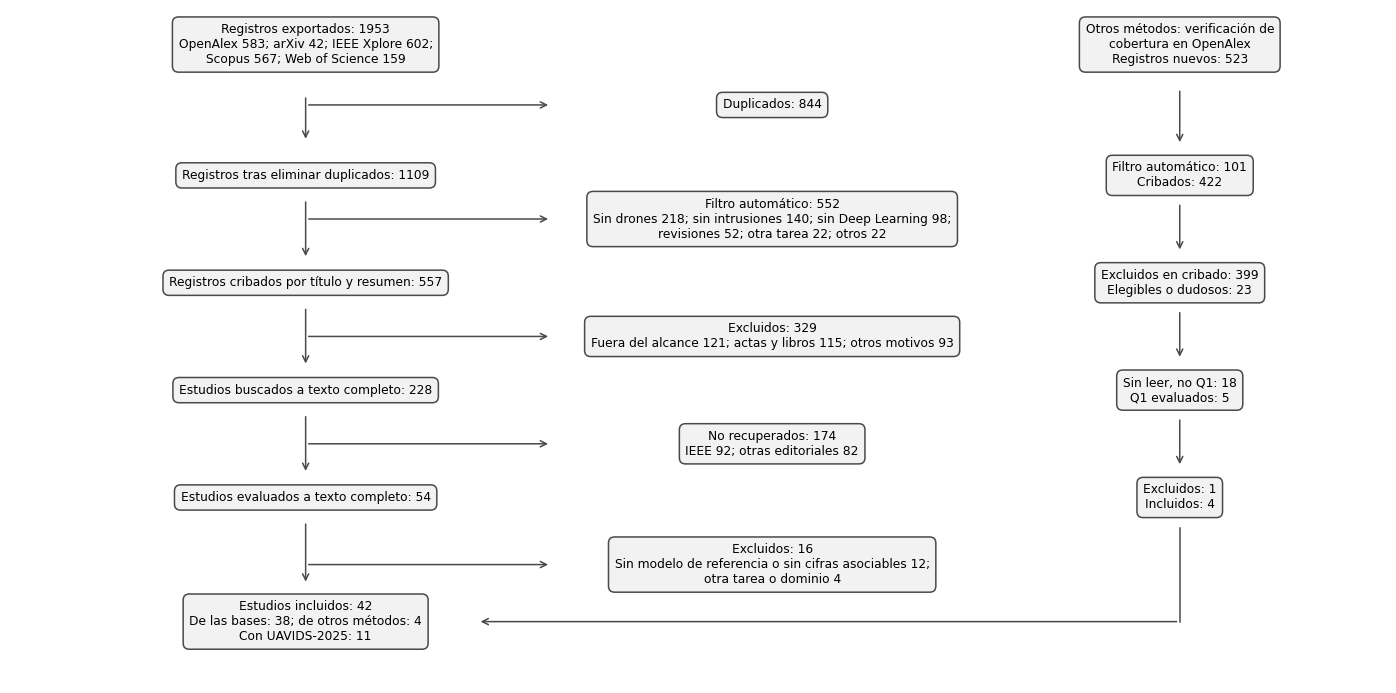

In [17]:
CONTEOS_PRISMA = {'exportados': 1953, 'duplicados': 844, 'depurados': 1109, 'filtro': 552, 'cribados': 557, 'excluidos_cribado': 329, 'buscados': 228, 'no_recuperados': 174, 'evaluados': 54, 'incluidos': 42, 'incluidos_bases': 38, 'excluidos_texto': 16, 'cob_nuevos': 523, 'cob_cribados': 422, 'cob_filtro': 101, 'cob_elegibles': 23, 'cob_excluidos_cribado': 399, 'cob_q1': 5, 'cob_sin_leer': 18, 'cob_incluidos': 4, 'cob_excluidos_texto': 1, 'con_uavids': 11, 'texto_exportados': 'OpenAlex 583; arXiv 42; IEEE Xplore 602;\nScopus 567; Web of Science 159', 'texto_filtro': 'Sin drones 218; sin intrusiones 140; sin Deep Learning 98;\nrevisiones 52; otra tarea 22; otros 22', 'texto_cribado': 'Fuera del alcance 121; actas y libros 115; otros motivos 93', 'texto_no_recuperados': 'IEEE 92; otras editoriales 82', 'texto_excluidos': 'Sin modelo de referencia o sin cifras asociables 12;\notra tarea o dominio 4'}
fig, eje = plt.subplots(figsize=(12.8, 6.4))
eje.axis("off")
eje.set(xlim=(0, 14), ylim=(0, 10))
c = CONTEOS_PRISMA


def caja(x, y, texto):
    eje.text(x, y, texto, ha="center", va="center", fontsize=8, bbox={"boxstyle": "round,pad=0.5", "facecolor": "#f2f2f2", "edgecolor": "#4a4a4a"})


def flecha(inicio, fin):
    eje.annotate("", xy=fin, xytext=inicio, arrowprops={"arrowstyle": "->", "color": "#4a4a4a"})


caja(3, 9.5, f"Registros exportados: {c['exportados']}\n{c['texto_exportados']}")
caja(3, 7.55, f"Registros tras eliminar duplicados: {c['depurados']}")
caja(3, 5.95, f"Registros cribados por título y resumen: {c['cribados']}")
caja(3, 4.35, f"Estudios buscados a texto completo: {c['buscados']}")
caja(3, 2.75, f"Estudios evaluados a texto completo: {c['evaluados']}")
caja(3, 0.9, f"Estudios incluidos: {c['incluidos']}\nDe las bases: {c['incluidos_bases']}; de otros métodos: {c['cob_incluidos']}\nCon UAVIDS-2025: {c['con_uavids']}")
caja(7.75, 8.6, f"Duplicados: {c['duplicados']}")
caja(7.75, 6.9, f"Filtro automático: {c['filtro']}\n{c['texto_filtro']}")
caja(7.75, 5.15, f"Excluidos: {c['excluidos_cribado']}\n{c['texto_cribado']}")
caja(7.75, 3.55, f"No recuperados: {c['no_recuperados']}\n{c['texto_no_recuperados']}")
caja(7.75, 1.75, f"Excluidos: {c['excluidos_texto']}\n{c['texto_excluidos']}")
for a, b in [(8.75, 8.05), (7.2, 6.3), (5.6, 4.7), (4.0, 3.1), (2.4, 1.45)]:
    flecha((3, a), (3, b))
for y in (8.6, 6.9, 5.15, 3.55, 1.75):
    flecha((3, y), (5.5, y))
# Rama de otros métodos: verificación de cobertura de sinónimos en OpenAlex
caja(11.9, 9.5, f"Otros métodos: verificación de\ncobertura en OpenAlex\nRegistros nuevos: {c['cob_nuevos']}")
caja(11.9, 7.55, f"Filtro automático: {c['cob_filtro']}\nCribados: {c['cob_cribados']}")
caja(11.9, 5.95, f"Excluidos en cribado: {c['cob_excluidos_cribado']}\nElegibles o dudosos: {c['cob_elegibles']}")
caja(11.9, 4.35, f"Sin leer, no Q1: {c['cob_sin_leer']}\nQ1 evaluados: {c['cob_q1']}")
caja(11.9, 2.75, f"Excluidos: {c['cob_excluidos_texto']}\nIncluidos: {c['cob_incluidos']}")
for a, b in [(8.85, 8.0), (7.15, 6.4), (5.55, 4.8), (3.95, 3.2)]:
    flecha((11.9, a), (11.9, b))
eje.plot([11.9, 11.9], [2.3, 0.9], color="#4a4a4a", linewidth=1)
flecha((11.9, 0.9), (4.75, 0.9))
plt.tight_layout()
plt.show()

**Interpretación.** De 1953 registros exportados, 844 son duplicados, el filtro automático retira 552 y el cribado por título y resumen retira 329. Quedan 228 estudios elegibles, de los cuales se pudieron evaluar 54, es decir, el 24 %, y se incluyen 38. La verificación de cobertura agrega 4 por la rama de otros métodos, para un total de 42. El artículo que presenta el conjunto de datos no menciona Deep Learning en su resumen y el filtro automático lo retiró; se rescató a mano. Ese artículo reporta los valores, pero no describe las arquitecturas, que están en el código público de los autores (Zeng, 2025).

Hay que tener en cuenta que esta lectura parcial introduce un sesgo: quedan sin evaluar 174 estudios, 92 de ellos de IEEE. Además, la lectura no fue uniforme, porque se priorizaron los de mayor cuartil y los de acceso abierto: se evaluaron 28 de los 68 elegibles Q1 y 26 de los 160 restantes, y en la verificación de cobertura se leyeron los 5 Q1 y ninguno de los 18 restantes. Por tanto, la tabla de frecuencia no se puede leer como un censo de la literatura del tema.

Por lo anterior, conviene leer los conteos como una estimación de la práctica en el área, con mayor peso de las revistas Q1 y del acceso abierto.

**Quién realizó la selección.** Al ser un trabajo de autor único, hubo un solo revisor y no hubo desacuerdos que resolver, lo cual es una limitación frente a un cribado doble. El cribado y la extracción se hicieron con apoyo de un asistente de inteligencia artificial (Claude, de Anthropic) bajo la supervisión del autor. El autor descargó con el acceso de la biblioteca los textos Q1 que no estaban en acceso abierto. La extracción se apoyó en la búsqueda dirigida de las tablas y los pasajes de comparación de cada texto, no en su lectura íntegra, de modo que un dato que no se halló queda como no reportado o no identificado, aunque podría estar en una figura o en un material suplementario.

**Evaluación de la calidad de los estudios.** Para cada estudio se valoró la partición, las repeticiones, la dispersión, las pruebas estadísticas y el riesgo de fuga. Solo 2 de los 42 estudios agrupan filas relacionadas, por sesión o por nodo; 31 no reportan repeticiones, solo 8 reportan dispersión y 6 aplican alguna prueba.

En cuanto a la calidad de las fuentes, el enunciado pide preferir literatura Q1. Según el cuartil SJR 2025 de SCImago (2026), que se calcula con datos de Scopus, 26 estudios son Q1, 5 Q2, 2 Q3 y 1 Q4, mientras que 8 son conferencias, preprints o fuentes sin cuartil, entre ellas el artículo de los autores del conjunto de datos. Hay que tener en cuenta que el cuartil describe a la revista en 2025, no a cada artículo ni al año en que se publicó.

| Estudio | Cuartil SJR | Partición | Repeticiones | Dispersión | Prueba estadística | Riesgo de fuga | Nota |
|---|---|---|---|---|---|---|---|
| Abbas et al. (2026) | Q1 | no identificada | no reportadas | no | ninguna | No evaluable | Clientes federados con datos no IID |
| Abdulhammed et al. (2026) | Q2 | aleatoria 80/20 | no reportadas | no | ninguna | Alto: no agrupa filas relacionadas | No menciona excluir FlowID ni las IP, y un 100 % sugiere fuga |
| Aburasain (2024) | Q1 | aleatoria 70/30 | no reportadas | no | ninguna | Alto: no agrupa filas relacionadas | Conjuntos de IoT |
| Alharthi (2024) | Q2 | aleatoria 70/30 | no reportadas | no | t de Student entre los dos mejores | Alto: no agrupa filas relacionadas | Conjuntos genéricos |
| Alissa et al. (2022) | Q1 | 70/30 | no reportadas | no | ninguna | Alto: no agrupa filas relacionadas | Conjunto genérico, no de drones; compara con cifras publicadas |
| Alotaibi et al. (2024) | Q1 | aleatoria 80/20 y 70/30 | no reportadas | no | ninguna | Alto: no agrupa filas relacionadas |  |
| Alruwaili y Tunc (2026) | no está en SJR | aleatoria 80/20 | no reportadas | no | ninguna | Alto: no agrupa filas relacionadas | Preprint; conjuntos genéricos |
| Alsaraireh et al. (2026) | Q1 | estratificada 70/15/15 | varias ejecuciones | sí | ninguna | Alto: no agrupa filas relacionadas |  |
| Alshammari et al. (2024) | Q2 | aleatoria 80/20 | no reportadas | no | ninguna | Alto: no agrupa filas relacionadas | Conjuntos genéricos |
| Alshamrani y Alghamdi (2026) | Q1 | un tipo de ataque fuera en cada evaluación | no reportadas | sí | t pareada, p < 0,001 | Alto: no agrupa filas relacionadas | Su sección {ref}`5.3 <sec-5-3>` cita MLP, CNN y LSTM con cifras que no coinciden con su tabla 3 |
| Arulalan et al. (2023) | no está en SJR | aleatoria 70/30 | no reportadas | no | ninguna | Alto: no agrupa filas relacionadas |  |
| Ashraf et al. (2023) | Q1 | aleatoria 70/30 | no reportadas | no | ninguna | Alto: no agrupa filas relacionadas | Conjunto genérico, no de drones |
| Attaullah et al. (2026a) | Q1 | entrenamiento y prueba, no identifica agrupación | 10 | sí | t de Student | Alto: no agrupa filas relacionadas |  |
| Attaullah et al. (2026c) | Q1 | 5 pliegues estratificados, con 70/15/15 en cada uno | 5 pliegues | no | ninguna | Alto: no agrupa filas relacionadas | Compara con cifras publicadas |
| Attaullah et al. (2026b) | Q1 | 5 pliegues estratificados | 5 pliegues | no | ninguna | Alto: no agrupa filas relacionadas | Compara con cifras publicadas |
| Babu et al. (2024) | Q1 | aleatoria 80/20 y 70/30 | no reportadas | no | ninguna | Alto: no agrupa filas relacionadas | Repite las cifras de comparación de 10.1109/access.2024.3392618 |
| Bakiri et al. (2026) | Q1 | por nodo de origen en UAVIDS-2025; estratificada 72/8/20 en UAV-NIDD | no reportadas | no | ninguna | Menor: agrupa por sesión o por nodo | Audita el archivo: 8219 filas repetidas y FlowID sin identificador de simulación |
| Balgoon (2026) | no está en SJR | aleatoria estratificada, 72 % de entrenamiento | no reportadas | no | ninguna | Alto: no agrupa filas relacionadas | Usa las IP como nodos del grafo |
| Batur Şahin (2026) | Q1 | estratificada 70/15/15 | 5 semillas | sí | ninguna | Alto: no agrupa filas relacionadas | Una CNN publicada aparece solo en una tabla de posicionamiento con otros conjuntos de datos, y no se cuenta |
| Biswas et al. (2026) | Q1 | estratificada por sesión de captura y dron | 5 semillas | sí | ninguna | Menor: agrupa por sesión o por nodo | Agrupa por sesión y dron |
| Cengiz et al. (2024) | Q1 | 5 pliegues | 5 pliegues | no | ninguna | Alto: no agrupa filas relacionadas |  |
| Gharami y Moni (2025) | no está en SJR | aleatoria 80/20 | no reportadas | no | ninguna | Alto: no agrupa filas relacionadas |  |
| Hadi et al. (2024) | Q1 | 80/20 | no reportadas | no | ninguna | Alto: no agrupa filas relacionadas |  |
| Hadi et al. (2026) | Q1 | no identificada | no reportadas | no | ninguna | No evaluable |  |
| Hakeem et al. (2025) | Q2 | aleatoria 70/30 | no reportadas | no | ninguna | Alto: no agrupa filas relacionadas |  |
| Hamad et al. (2025) | Q3 | no identificada | no reportadas | no | ninguna | No evaluable | Conjunto genérico; compara con cifras publicadas |
| Junaid et al. (2026) | Q1 | estratificada 70/15/15, con SMOTE solo en entrenamiento | no reportadas | no | ninguna | Alto: no agrupa filas relacionadas | Usa los mismos 16 atributos |
| Katbar et al. (2024) | Q3 | aleatoria 80/20 | no reportadas | no | ninguna | Alto: no agrupa filas relacionadas |  |
| Katib et al. (2025) | Q1 | 80/20 y 70/30 | no reportadas | no | ninguna | Alto: no agrupa filas relacionadas | Los autores advierten que no aplican pruebas estadísticas |
| Li et al. (2026a) | Q1 | aleatoria 90/10 | no reportadas | no | ninguna | Alto: no agrupa filas relacionadas |  |
| Li et al. (2026b) | Q1 | 90/10 | 10 | sí | ninguna | Alto: no agrupa filas relacionadas |  |
| Menssouri et al. (2024) | sin cuartil | aleatoria | no reportadas | no | ninguna | Alto: no agrupa filas relacionadas |  |
| Mohamed et al. (2026) | Q1 | 70/15/15; además, un ataque fuera | no reportadas | sí | p < 0,01, sin nombrar la prueba en los pasajes revisados | Alto: no agrupa filas relacionadas |  |
| Negm et al. (2024) | Q1 | 80/20 y 70/30 | no reportadas | no | ninguna | Alto: no agrupa filas relacionadas | Conjunto genérico; la descripción del autoencoder menciona señales EEG, ajenas al problema |
| Ozsoy et al. (2026) | Q4 | aleatoria 80/20, con 176 clientes por IP de origen | no reportadas | no | ninguna sobre modelos | Alto: no agrupa filas relacionadas |  |
| SureshBabu y Geetha (2026) | no está en SJR | no identificada | no reportadas | no | ninguna | No evaluable | Compara con cifras publicadas de otros conjuntos |
| Tan et al. (2019) | Q1 | aleatoria; usa 10 % del archivo | no reportadas | no | ninguna | Alto: no agrupa filas relacionadas | Conjunto genérico, no de drones |
| Wang et al. (2026) | Q1 | aleatoria, con validación cruzada | 5 semillas | sí | t de Student pareada | Alto: no agrupa filas relacionadas | No menciona excluir FlowID ni las IP; sus cifras superan a las de los autores |
| Wu et al. (2024) | Q1 | entrenamiento con parte de los ataques; prueba más de diez veces mayor | no reportadas | no | ninguna | Alto: no agrupa filas relacionadas | Conjuntos genéricos, no de drones |
| Zarkadis y Douligeris (2026) | no está en SJR | aleatoria estratificada 80/20, con 10 pliegues en entrenamiento | 10 pliegues | no | permutación sobre atributos, no sobre modelos | Alto: no agrupa filas relacionadas | Codifica las IP por frecuencia |
| Zeng et al. (2025) | no está en SJR | aleatoria estratificada 80/20 | no reportadas | no | ninguna | Alto: no agrupa filas relacionadas | El artículo reporta los resultados; la arquitectura está en el código de los autores |
| Zhou et al. (2026) | Q2 | 5 pliegues | 5 pliegues | no | ninguna | Alto: no agrupa filas relacionadas | Conjuntos genéricos |

(sec-3-2)=
## 3.2 Identificación de los tres modelos base de Deep Learning

**Procedimiento de extracción.** En cada estudio incluido se revisó qué modelos de Deep Learning se emplean como referencia, se registró su arquitectura y configuración cuando se reportan, y se normalizó cada modelo por familia. Con esto se construye la tabla de frecuencia, se ordenan los candidatos por frecuencia y complejidad, se seleccionan tres y se verifica que no sean redundantes.

**Tabla de síntesis.** Los valores se transcriben como los reporta cada estudio, en su propia métrica y con su propio conjunto de datos.

| Referencia | Problema | Dataset | Modelos de Deep Learning de referencia | Métricas reportadas y valores |
|---|---|---|---|---|
| Abbas et al. (2026) | Detección de intrusiones en drones: flujos de red simulados | UAVIDS-2025 | FL-CNN, FL-RNN y FL-MLP (CNN; RNN; DNN/MLP) | Precisión en Wormhole: FL-CNN 0,70, FL-RNN 0,78, FL-MLP 0,78 y FL-GCN 0,81; en Blackhole: 0,90, 0,92, 0,94 y 0,92 |
| Abdulhammed et al. (2026) | Detección de intrusiones en drones: flujos de red simulados | UAVIDS-2025 y UAV-GCS | FFN de 128 y 64, LSTM de 64 y CNN 1D (DNN/MLP; LSTM; CNN) | En UAVIDS-2025, el texto da 97,65 % de exactitud para FFN y 100 % para LightGBM |
| Aburasain (2024) | Detección de intrusiones en drones: flujos de red | ToN-IoT y Edge-IIoTset | LSTM y GRU (LSTM; GRU) | Exactitud: LSTM de 96,20 a 96,95 %, GRU de 96,00 a 96,50 % |
| Alharthi (2024) | Detección de intrusiones en drones: flujos de red | KDD Cup 99, NSL-KDD, WSN-DS y CICIDS | CNN, LSTM y CNN-LSTM (CNN; LSTM; CNN-LSTM) | Exactitud en una de las tablas: CNN 89,10 %, LSTM 92,25 %, CNN-LSTM 95,11 %; propuesto 99,99 % |
| Alissa et al. (2022) | Detección de intrusiones en drones: flujos de red | 8000 registros con las clases de NSL-KDD | MLP, junto con cinco modelos clásicos, tomados de un trabajo publicado (DNN/MLP) | Exactitud: propuesto 99,12 %, MLP 90,03 % |
| Alotaibi et al. (2024) | Detección de intrusiones en drones: flujos de red | no identificado | IDBN y DPC-DBN (DBN) | Exactitud: IDBN 95,32 %, DPC-DBN 94,39 % |
| Alruwaili y Tunc (2026) | Detección de intrusiones en drones: flujos de red | UNSW-NB15 y Edge-IIoT | DNN, CNN 1D y CNN 1D con LSTM (DNN/MLP; CNN; CNN-LSTM) | Mejora de exactitud de 0,83 a 4,98 % en UNSW-NB15 |
| Alsaraireh et al. (2026) | Detección de intrusiones en drones: flujos de red | tres conjuntos UAV-IDS | CNN 1D como modelo base del detector (CNN) | Exactitud sin perturbar: 95,27 % en un conjunto y 78,93 % en UAV3-IDS |
| Alshammari et al. (2024) | Detección de intrusiones en drones: flujos de red | NSL-KDD y TON_IoT | LSTM-RNN y CNN (LSTM; CNN) | Exactitud en NSL-KDD: LSTM-RNN 95,91 %, CNN 86,54 %; propuesto 99,32 % |
| Alshamrani y Alghamdi (2026) | Detección de intrusiones en drones: flujos de red | UAV-NIDD | LSTM y FlowTransformer supervisados, como cota superior (LSTM; Transformer) | F1 supervisado: LSTM 94,5 ± 0,7 % y FlowTransformer 95,8 ± 0,6 %; propuesto 85,6 ± 0,8 % sin haber visto el ataque |
| Arulalan et al. (2023) | Detección de intrusiones en drones: flujos de red | CICIDS2017 | CNN-LSTM, CNN y EDFFNN (CNN-LSTM; CNN; DNN/MLP) | No se pudieron asociar las cifras a cada modelo en el texto |
| Ashraf et al. (2023) | Detección de intrusiones en drones: flujos de red | CICIDS2017 y otros | RNN, LSTM y Bi-LSTM de 64 unidades, GRU y perceptrón (RNN; LSTM; BiLSTM; GRU; DNN/MLP) | Exactitud: Bi-LSTM 91,36 %, LSTM 91,00 %, RNN 90,16 %, GRU 89,13 %, perceptrón 85,02 % |
| Attaullah et al. (2026a) | Detección de intrusiones en drones: datos del sistema | T-ITS, ciberfísico de UAV | DNN (DNN/MLP) | Exactitud: DNN 96,43 ± 0,22 %; propuesto 98,74 ± 0,07 % |
| Attaullah et al. (2026c) | Detección de intrusiones en drones: datos del sistema | T-ITS | FFCNN y MC-DNN, tomados de trabajos publicados (CNN; DNN/MLP) | Exactitud del propuesto: 99,44 % |
| Attaullah et al. (2026b) | Detección de intrusiones en drones: flujos de red | conjunto multimodal de UAV | GAN-MCNN-DFS, ANN, CNN, XAI-DNN y SEMI-GRU, tomados de trabajos publicados (CNN; DNN/MLP; GRU) | Exactitud del propuesto: 99,49 % |
| Babu et al. (2024) | Detección de intrusiones en drones: flujos de red | no identificado | IDBN y DPC-DBN (DBN) | Exactitud: IDBN 95,32 %, DPC-DBN 94,39 %; propuesto 99,63 % |
| Bakiri et al. (2026) | Detección de intrusiones en drones: flujos de red simulados | UAVIDS-2025 y UAV-NIDD | KAN plana; DNN-KDQ y UAV-IDS-ConvNet, de trabajos publicados (KAN; DNN/MLP; CNN) | Exactitud en cinco clases en UAVIDS-2025: 92,50 %; KAN plana 93,35 % |
| Balgoon (2026) | Detección de intrusiones en drones: flujos de red simulados | UAVIDS-2025 y T-ITS | BiLSTM, GNN y autoencoder (BiLSTM; GNN; Autoencoder) | F1 macro: BiLSTM 77,87 %, GNN 94,60 %; propuesto 98,18 % |
| Batur Şahin (2026) | Detección de intrusiones en drones: registros de vuelo y tráfico MAVLink | UAV Attack Dataset, de IEEE DataPort | Clasificador feedforward solo, como línea base de la ablación (DNN/MLP) | Exactitud: clasificador 92,23 ± 0,3 % (F1 0,9198); propuesto centralizado 98,67 ± 0,2 % (F1 0,9856) |
| Biswas et al. (2026) | Detección de intrusiones en drones: flujos de red | ISOT Drone Anomaly Detection | CNN 1D, MLP, GRU, LSTM y RNN (CNN; DNN/MLP; GRU; LSTM; RNN) | Exactitud del propuesto: 99,99 % |
| Cengiz et al. (2024) | Detección de intrusiones en drones: datos del sistema | UAV con ataques de GPS | Red de retropropagación, con y sin una capa adicional (DNN/MLP) | Exactitud: BPN 0,895, BPN con una capa más 0,9324 |
| Gharami y Moni (2025) | Detección de intrusiones en drones: flujos de red | UAV IDS, UKM IDS y otros | MLP-AE, L-MADE y FFCNN (Autoencoder; CNN) | Exactitud en UAV IDS: FFCNN 99,99 %, MLP-AE 98,81 %; propuesto 99,99 % |
| Hadi et al. (2024) | Detección de intrusiones en drones: flujos de red | UAVIDS-2020, NF-UQ-NIDS-v2 y 5G-NIDD | DNN simple y DNN multinivel simple (DNN/MLP) | Exactitud en UAVIDS-2020: fusión 99,95 %, multinivel 98,91 %, DNN simple 94,78 % |
| Hadi et al. (2026) | Detección de intrusiones en drones: flujos de red | GCS-NIDD | TabNet, junto con LightGBM y BLS (TabNet) | Exactitud por modelo: TabNet 93,10 %, LightGBM 90,20 %, BLS 89,70 %; fusión 99,30 % |
| Hakeem et al. (2025) | Detección de intrusiones en drones: datos del sistema | datos ciberfísicos de GPS | MLP, CNN, LSTM y ResNet (DNN/MLP; CNN; LSTM; ResNet) | Exactitud: ResNet 90,99 %, MLP 89,49 %, CNN 86,36 %, LSTM 82,45 % |
| Hamad et al. (2025) | Detección de intrusiones en drones: flujos de red | CIC-IDS 2017 | CNN-GRU y LSTM-CNN, tomados de trabajos publicados (CNN-LSTM; GRU) | Exactitud: CNN-GRU 98,73 %, LSTM-CNN 99,21 %; propuesto: F1 99,28 % |
| Junaid et al. (2026) | Detección de intrusiones en drones: flujos de red simulados | UAVIDS-2025 | MLP, junto con cuatro modelos clásicos (DNN/MLP) | Binario: MLP exactitud 99,1 % y F1 99,5 %; propuesto 97,7 % y 98,5 %; XGBoost 99,6 % y 99,7 % |
| Katbar et al. (2024) | Detección de intrusiones en drones: flujos de red | no identificado | LSTM y CNN (LSTM; CNN) | Exactitud: LSTM 93 %, CNN 93 %; propuesto 95 % |
| Katib et al. (2025) | Detección de intrusiones en drones: flujos de red | InSDN | AlexNet, ResNet y ShuffleNet, tomados de trabajos publicados (CNN; ResNet) | Exactitud del propuesto: 99,88 % |
| Li et al. (2026a) | Detección de intrusiones en drones: flujos de red | UAV-IDS-2020 | CNN 1D como modelo base del detector (CNN) | Tasa de éxito del ataque sobre la CNN: 93,61 % |
| Li et al. (2026b) | Detección de intrusiones en drones: flujos de red | UAV-NIDD y CICIoT2022 | FS-Net, ET-BERT, YaTC, GraphDAPP, TFE-GNN y FNN (RNN; Transformer; GNN; DNN/MLP) | F1 en UAV-NIDD: TGE-ETD 99,97 ± 0,04 %, YaTC 99,96 ± 0,77 %, FNN 95,20 %, TFE-GNN 93,01 ± 2,14 %, MAML 71,09 % |
| Menssouri et al. (2024) | Detección de intrusiones en drones: flujos convertidos a matriz | UAV-IDS-2020 | CNN 1D y CNN 1D con PCA (CNN) | CNN 1D: exactitud cerca de 75 % en modo BF; propuesto 99,99 % |
| Mohamed et al. (2026) | Detección de intrusiones en drones: flujos de red simulados | UAVIDS-2025, UNSW-NB15 y ET-BERT | DAE, CNN-GRU, GCN, GNN-Adv, TodyNet y GTCN-G (Autoencoder; CNN-LSTM; GNN) | F1 en UAVIDS-2025: AD-GNN 0,962 ± 0,003, TodyNet 0,941 |
| Negm et al. (2024) | Detección de intrusiones en drones: flujos de red | NSL-KDD | IDBN y DPC-DBN, junto con DRL-BWO, T-SID, un modelo de Deep Learning sin especificar y AK-NN, tomados de trabajos publicados (DBN) | Exactitud: propuesto 99,36 %, IDBN 95,32 %, DPC-DBN 94,39 % |
| Ozsoy et al. (2026) | Detección de intrusiones en drones: flujos de red simulados | UAVIDS-2025 y T-ITS | MLP compacto federado; DNN, CNN y LSTM de los autores del conjunto de datos (DNN/MLP; CNN; LSTM) | F1: FedAvg 93 %, FedProx 84 %; referencias de los autores: DNN 93 %, CNN 93 %, LSTM 94 % |
| SureshBabu y Geetha (2026) | Detección de intrusiones en drones: flujos de red simulados | UAVIDS-2025 | ANN-GA y ConvLSTM, tomados de trabajos publicados (DNN/MLP; CNN-LSTM) | Exactitud: ANN-GA 91,8 %, ConvLSTM 95,3 %; propuesto 98,7 % |
| Tan et al. (2019) | Detección de intrusiones en drones: flujos de red | KDD Cup 99 | ANN y DNN (DNN/MLP) | Exactitud: ANN 90,79 %, DNN 91,36 %; propuesto 92,44 % |
| Wang et al. (2026) | Detección de intrusiones en drones: flujos de red simulados | UAVIDS-2025 | CNN, RNN, LSTM, ANN y BiLSTM (CNN; LSTM; RNN; DNN/MLP; BiLSTM) | LSTM de dos capas: F1 98,60 %; propuesto: exactitud 99,68 ± 0,12 % |
| Wu et al. (2024) | Detección de intrusiones en drones: flujos de red | CSE-CIC-IDS2018 y CIC-DDoS2019 | VCDL, CNN3D, LSTM, SNDA, SCA+SVM y CGAN (CNN; LSTM; Autoencoder; GAN) | El propuesto alcanza 99 % de exactitud en CIC-DDoS2019; las tablas de comparación no se pudieron extraer |
| Zarkadis y Douligeris (2026) | Detección de intrusiones en drones: flujos de red simulados | UAVIDS-2025 | MLP y RealMLP (DNN/MLP) | F1 de prueba: MLP 90,66 %, RealMLP 94,28 % |
| Zeng et al. (2025) | Detección de intrusiones en drones: flujos de red simulados | UAVIDS-2025 | DNN 16-128-64-32-5; CNN 1D de 32 y 64 filtros; LSTM de 64 unidades; las tres con dropout de 0,2 (DNN/MLP; CNN; LSTM) | F1: DNN 93 %, CNN 93 %, LSTM 94 %; regresión logística 82 %, XGBoost 96 % |
| Zhou et al. (2026) | Detección de intrusiones en drones: flujos de red | ISCXVPN2016, CICIDS-2018, TON IoT y CIC IoT 2023 | CNN, LSTM, Transformer y BPNN de 512, 256 y 128 (CNN; LSTM; Transformer; DNN/MLP) | Exactitud en ISCXVPN2016: LSTM 95,9 %, CNN 94,95 % |

**Tabla de frecuencia.** Un estudio cuenta una vez por familia, aunque use varias variantes.

| Modelo | Estudios (n = 42) | % | Estudios con UAVIDS-2025 (n = 11) | % con UAVIDS-2025 | Estudios Q1 (n = 26) |
|---|---|---|---|---|---|
| DNN/MLP | 24 | 57,1 | 9 | 81,8 | 15 |
| CNN | 22 | 52,4 | 6 | 54,5 | 10 |
| LSTM | 14 | 33,3 | 4 | 36,4 | 6 |
| CNN-LSTM | 6 | 14,3 | 2 | 18,2 | 1 |
| RNN | 5 | 11,9 | 2 | 18,2 | 5 |
| GRU | 5 | 11,9 | 0 | 0,0 | 4 |
| Autoencoder | 4 | 9,5 | 2 | 18,2 | 2 |
| BiLSTM | 3 | 7,1 | 2 | 18,2 | 2 |
| DBN | 3 | 7,1 | 0 | 0,0 | 3 |
| Transformer | 3 | 7,1 | 0 | 0,0 | 2 |
| GNN | 3 | 7,1 | 2 | 18,2 | 2 |
| ResNet | 2 | 4,8 | 0 | 0,0 | 1 |
| GAN | 1 | 2,4 | 0 | 0,0 | 1 |
| TabNet | 1 | 2,4 | 0 | 0,0 | 1 |
| KAN | 1 | 2,4 | 1 | 9,1 | 1 |

**Interpretación.** La DNN o MLP y la CNN son las referencias más frecuentes, con 24 y 22 estudios, seguidas de la LSTM, con 14. El cuarto lugar, la combinación de CNN con LSTM, tiene 6 estudios, así que el corte no es ambiguo. El orden se mantiene en los 11 estudios que usan UAVIDS-2025, donde estas tres familias también son las más usadas. Con solo los 26 estudios Q1, DNN/MLP tiene 15, CNN 10 y LSTM 6, por delante de RNN (5).

Esto significa que la selección no depende de un criterio personal, porque en el total los tres primeros lugares están claramente separados del resto. Hay que tener en cuenta que, entre los Q1, LSTM supera a la RNN simple, que tiene menor complejidad, por 1 estudio, gracias a los Q1 de la verificación de cobertura, y en el total la supera por 9. Ese margen es estrecho entre los Q1 y quedan 40 estudios Q1 sin leer, de modo que podría cambiar con más lecturas.

Por tal motivo, se opta por estas tres familias como modelos base.

**Arquitectura y configuración reportadas.** El paso 2 del procedimiento pide registrar la profundidad, el ancho, la regularización y el entrenamiento de cada modelo de referencia. La tabla reúne lo que se halló en la búsqueda dirigida de cada texto; lo que falta en ella queda como no reportado, aunque podría estar en una figura o en un material suplementario.

| Referencia | Modelo | Arquitectura | Regularización | Entrenamiento | Fuente del dato |
|---|---|---|---|---|---|
| Zeng (2025) | DNN | 3 capas ocultas: 128, 64 y 32 | Dropout de 0,2 tras las capas de 128 y 64 | Adam, tasa de 0,001, lote de 256, máximo 50 épocas, parada temprana con paciencia de 5 | Código de los autores |
| Zeng (2025) | CNN 1D | 2 convoluciones de 32 y 64 filtros de tamaño 3, max-pooling y densa de 64 | Dropout de 0,2 antes de la capa densa | Adam, tasa de 0,001, lote de 256, máximo 50 épocas, parada temprana con paciencia de 5 | Código de los autores |
| Zeng (2025) | LSTM | 1 capa de 64 unidades | Dropout de 0,2 antes de la salida | Adam, tasa de 0,001, lote de 256, máximo 50 épocas, parada temprana con paciencia de 5 | Código de los autores |
| Abdulhammed et al. (2026) | FFN (tabla de uav-gcs) | 2 capas ocultas: 128 y 64 | Dropout de 0,3 | Adam, 50 épocas, lote de 32 | Tabla 7 |
| Abdulhammed et al. (2026) | LSTM (tabla de uav-gcs) | 2 capas de 64 y 32 unidades | Dropout de 0,2 | Adam, 50 épocas, lote de 32, parada temprana con paciencia de 10 | Tabla 8 |
| Abdulhammed et al. (2026) | 1DCNN (tabla de uav-gcs) | Convoluciones de 64 y 128 filtros de tamaño 3, max-pooling de 2 y densa de 128 | Dropout de 0,2 y 0,5 | Adam, lote de 64 | Tabla 9 |
| Ashraf et al. (2023) | RNN (el lote aparece con dos valores en la misma tabla) | 64 unidades; capas no reportadas | Dropout de 0,2 | Adam, 20 épocas; lote reportado dos veces, 24 y 864 | Tabla 2 |
| Ashraf et al. (2023) | LSTM (el lote aparece con dos valores en la misma tabla) | 64 unidades; capas no reportadas | Dropout de 0,2 | Adam, 20 épocas; lote reportado dos veces, 24 y 1152 | Tabla 2 |
| Ashraf et al. (2023) | Bi-LSTM (el lote aparece con dos valores en la misma tabla) | 64 unidades; capas no reportadas | Dropout de 0,2 | Adam, 20 épocas; lote reportado dos veces, 24 y 1152 | Tabla 2 |
| Zhou et al. (2026) | BPNN | 3 capas ocultas: 512, 256 y 128 | Dropout de 0,2 | No reportado | Texto |
| Zhou et al. (2026) | Transformer | 2 capas, 4 cabezas y dimensión de 128 | No reportado | Adam, tasa de 0,001, lote de 64 | Texto |
| Hakeem et al. (2025) | MLP (clasificación binaria) | Capa oculta de 64 y entrada de 32 | Dropout de 0,2 | No reportado | Texto |
| Hakeem et al. (2025) | CNN (clasificación binaria) | Convolución y max-pooling, sin número de filtros | Dropout de 0,2 y 0,5 | No reportado | Texto |
| Ozsoy et al. (2026) | MLP federado | 2 capas ocultas: 64 y 32 | Dropout, normalización por lotes y decaimiento de pesos L2 | Adam con tasa coseno | Texto |
| Balgoon (2026) | BiLSTM (componente del modelo propuesto) | 2 capas de 128 unidades | Dropout de 0,3 | No reportado | Texto |
| Balgoon (2026) | GNN (componente del modelo propuesto) | 3 capas GATv2 de ancho 64, con 8, 4 y 1 cabezas | No reportado | No reportado | Texto |
| Balgoon (2026) | Autoencoder (componente del modelo propuesto) | No extraída | No reportado | Adam, tasa de 0,001, 150 épocas, lote de 256 | Texto |
| Biswas et al. (2026) | CNN 1D (conjunto isot) | 2 bloques Conv1D de tamaño 3, con normalización por lotes y max-pooling de 2 | Dropout de 0,3 | No extraído | Texto |
| Biswas et al. (2026) | GRU (conjunto isot) | 2 capas de 128 y 64 unidades | Dropout de 0,3 y normalización por lotes | No extraído | Texto |
| Biswas et al. (2026) | RNN (conjunto isot) | 2 capas SimpleRNN, la primera de 128 unidades | No extraído | No extraído | Texto |
| Alsaraireh et al. (2026) | CNN 1D | Capas no extraídas | Dropout de 0,3 | Tasa de 0,001, lote de 2048, 20 épocas, parada temprana con paciencia de 5 | Tabla 8 |
| Li et al. (2026a) | CNN 1D | Convoluciones 1D con ReLU y pooling, sin número de capas | No reportado | No reportado | Texto |
| Bakiri et al. (2026) | KAN plana (conjunto uavids-2025) | 6039 parámetros, en 23,59 KB | No reportado | Igual a la del modelo propuesto | Tabla 7 |
| Batur Şahin (2026) | Clasificador sin VAE (línea base de la ablación) | 3 capas ocultas: 256, 128 y 64 | Dropout, sin tasa reportada | Tasa de 0,001 con recocido coseno, lote de 128, 100 épocas | Ecuaciones 6 a 9 y sección 4 |

**Interpretación.** Solo 12 de los 42 estudios incluidos describen al menos un modelo de referencia, y en los otros 30 el modelo se nombra sin su arquitectura. Además, varios datos no provienen del conjunto principal de cada estudio ni de un modelo de referencia puro: las tablas de Abdulhammed et al. (2026) corresponden a UAV-GCS, y los de Balgoon (2026) son componentes de su modelo propuesto.

Hay que tener en cuenta que el enunciado excluye los estudios sin descripción suficiente de la arquitectura de referencia, y que en esta revisión ese criterio se aplicó exigiendo que el modelo de referencia y sus cifras se pudieran identificar, no que se describiera su arquitectura. Es decir, una aplicación estricta dejaría 12 estudios, y por eso se contrasta la frecuencia con ese subconjunto:

| Familia | Estudios que la describen (n = 12) | Estudios que la usan (n = 42) |
|---|---|---|
| CNN | 6 | 22 |
| DNN/MLP | 6 | 24 |
| LSTM | 3 | 14 |
| BiLSTM | 2 | 3 |
| RNN | 2 | 5 |
| Autoencoder | 1 | 4 |
| GNN | 1 | 3 |
| GRU | 1 | 5 |
| KAN | 1 | 1 |
| Transformer | 1 | 3 |

Con esa restricción, CNN y DNN/MLP siguen en los primeros lugares, con 6 y 6 estudios, y LSTM sigue a continuación, con 3, frente a 2 de BiLSTM, que además es una variante más compleja de LSTM, y 2 de RNN. Por lo anterior, se conservan los tres modelos, con la salvedad de que en el subconjunto estricto el margen es de un solo estudio. Esto también respalda tomar la arquitectura del código de los autores (Zeng, 2025), porque es la única que se halló con las tres familias sobre UAVIDS-2025.

**Selección de los tres modelos.** Dentro de cada familia se toma la variante más simple con arquitectura publicada. Zeng et al. (2025) nombran los tres modelos en su artículo, pero no describen sus capas, que están en el código público de los mismos autores (Zeng, 2025). Como la arquitectura sí está definida, no aplica la búsqueda de arquitectura de la sección 14 del Entregable 2.

| Modelo | Arquitectura tomada de | Parámetros | Capas con pesos | Multiplicaciones por muestra |
|---|---|---|---|---|
| DNN | Zeng (2025) | 12 677 | 4 | 12 448 |
| LSTM | Zeng (2025) | 17 477 | 2 | 266 560 |
| CNN 1D | Zeng (2025) | 39 493 | 4 | 132 928 |

Los parámetros y las multiplicaciones se calculan para una entrada de 16 atributos y 5 clases, y el código de la sección {ref}`4.2.1 <sec-4-2-1>` verifica el conteo de parámetros.

**Verificación de que no son redundantes.** Los tres modelos difieren en el sesgo inductivo que incorporan. La DNN combina todos los atributos desde la primera capa, sin suponer ningún orden entre ellos. La CNN 1D busca patrones locales entre atributos vecinos y comparte pesos a lo largo del vector. La LSTM lee los atributos uno a la vez y acumula un estado. Hay que tener en cuenta que el orden de las columnas de una tabla no tiene significado físico, de modo que la CNN y la LSTM imponen una estructura que los datos no garantizan, y justamente por eso la comparación permite medir si ese supuesto ayuda o estorba. Para que sea reproducible, la secuencia sigue el orden de las columnas del archivo.

**Equivalencia con los modelos clásicos de referencia.** El enunciado asigna a estos modelos el papel que cumple el modelo logístico en clasificación, y la equivalencia se sustenta en tres aspectos. En capacidad de representación, los tres modelos terminan en una capa lineal con softmax:

$$p_\theta(c \mid x) = \frac{\exp\left(w_c^\top \phi_\theta(x)\right)}{\sum_{k=1}^{K} \exp\left(w_k^\top \phi_\theta(x)\right)}$$

Es decir, son una regresión logística multinomial sobre una representación aprendida $\phi_\theta(x)$, y si $\phi_\theta$ fuera la identidad, el modelo sería exactamente el logístico. En supuestos, el logístico supone clases separables por un hiperplano en el espacio de entrada, mientras que estos modelos solo lo suponen en el espacio de $\phi_\theta$. En propósito comparativo, ambos fijan un piso con la misma pérdida, la entropía cruzada: un modelo avanzado que no los supere no justifica su mayor complejidad.

(sec-3-3)=
## 3.3 Análisis detallado por modelo base

Todos los modelos comparten la pérdida, la entropía cruzada ponderada $\mathcal{L}(\theta) = -\frac{1}{n}\sum_i w_{y_i} \log p_\theta(y_i \mid x_i)$, y resuelven la clasificación multiclase de flujos de red de la sección 1. Las referencias completas de cada estudio están en la sección 9, y la configuración de entrenamiento de referencia es la del código de los autores (Zeng, 2025): Adam con tasa de aprendizaje de 0,001, lotes de 256, un máximo de 50 épocas y parada temprana. La figura siguiente resume el flujo de datos de los tres modelos, que después se detalla para cada uno.

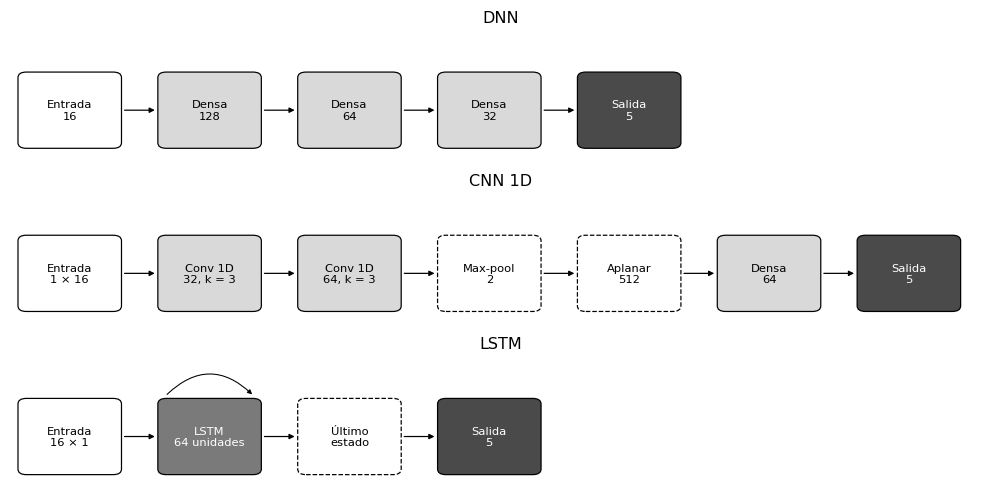

**Interpretación.** La figura muestra el flujo de datos de cada modelo, de izquierda a derecha. Los bloques claros son capas con pesos, el de gris medio es la capa recurrente, con su lazo arriba, los punteados no tienen pesos, y los oscuros son la capa de salida. La DNN recibe el vector completo, la CNN 1D lo recorre con filtros de tamaño 3 y la LSTM lo lee como una secuencia de 16 pasos.

Esto significa que los tres modelos difieren en cómo combinan los atributos, y no solo en su número de parámetros: la DNN no supone ningún orden, mientras que la CNN 1D y la LSTM dependen del orden de las columnas.

Por tal motivo, se conservan estas tres arquitecturas como base, porque sus diferencias responden a supuestos distintos.

In [18]:
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

BLOQUES = {"DNN": [("Entrada\n16", "entrada"), ("Densa\n128", "densa"), ("Densa\n64", "densa"), ("Densa\n32", "densa"), ("Salida\n5", "salida")],
           "CNN 1D": [("Entrada\n1 × 16", "entrada"), ("Conv 1D\n32, k = 3", "conv"), ("Conv 1D\n64, k = 3", "conv"), ("Max-pool\n2", "resumen"), ("Aplanar\n512", "resumen"), ("Densa\n64", "densa"), ("Salida\n5", "salida")],
           "LSTM": [("Entrada\n16 × 1", "entrada"), ("LSTM\n64 unidades", "recurrente"), ("Último\nestado", "resumen"), ("Salida\n5", "salida")]}
ESTILO_BLOQUE = {"entrada": ("white", NEGRO, "-"), "conv": (GRIS_CLARO, NEGRO, "-"), "recurrente": (GRIS_MEDIO, "white", "-"), "resumen": ("white", NEGRO, "--"), "densa": (GRIS_CLARO, NEGRO, "-"), "salida": (GRIS_OSCURO, "white", "-")}
fig, ejes = plt.subplots(len(BLOQUES), 1, figsize=(9.2, 4.6))
for eje, (nombre, capas_modelo) in zip(ejes, BLOQUES.items()):
    for i, (texto, tipo) in enumerate(capas_modelo):
        fondo, letra, linea = ESTILO_BLOQUE[tipo]
        eje.add_patch(FancyBboxPatch((i + 0.06, 0.1), 0.72, 0.8, boxstyle="round,pad=0.01,rounding_size=0.06", facecolor=fondo, edgecolor=NEGRO, linestyle=linea, linewidth=0.8))
        eje.text(i + 0.42, 0.5, texto, ha="center", va="center", fontsize=7.5, color=letra)
        if i < len(capas_modelo) - 1:
            eje.add_patch(FancyArrowPatch((i + 0.79, 0.5), (i + 1.05, 0.5), arrowstyle="-|>", mutation_scale=7, color=NEGRO, linewidth=0.8))
        if tipo == "recurrente":
            eje.add_patch(FancyArrowPatch((i + 0.1, 0.93), (i + 0.74, 0.93), connectionstyle="arc3,rad=-0.5", arrowstyle="-|>", mutation_scale=6, color=NEGRO, linewidth=0.7))
    eje.set(xlim=(0, 7), ylim=(0, 1.35), xticks=[], yticks=[], title=nombre)
    eje.set_frame_on(False)
    eje.grid(False)
plt.tight_layout()
plt.show()
interpretar('''**Interpretación.** La figura muestra el flujo de datos de cada modelo, de izquierda a derecha. Los bloques claros son capas con pesos, el de gris medio es la capa recurrente, con su lazo arriba, los punteados no tienen pesos, y los oscuros son la capa de salida. La DNN recibe el vector completo, la CNN 1D lo recorre con filtros de tamaño 3 y la LSTM lo lee como una secuencia de 16 pasos.

Esto significa que los tres modelos difieren en cómo combinan los atributos, y no solo en su número de parámetros: la DNN no supone ningún orden, mientras que la CNN 1D y la LSTM dependen del orden de las columnas.

Por tal motivo, se conservan estas tres arquitecturas como base, porque sus diferencias responden a supuestos distintos.''')

### Modelo 1: DNN

- **Tipo de arquitectura.** Perceptrón multicapa.
- **Referencias que la respaldan.** Abbas et al. (2026), <https://doi.org/10.1109/ojcoms.2026.3698792>, Abdulhammed et al. (2026), <https://doi.org/10.70102/afts.2026.1836.229>, Alissa et al. (2022), <https://doi.org/10.3390/drones6100297>, Alruwaili y Tunc (2026), <https://doi.org/10.48550/arxiv.2607.17025>, Arulalan et al. (2023), <https://doi.org/10.17762/ijritcc.v11i9.8338>, Ashraf et al. (2023), <https://doi.org/10.1038/s41598-023-45065-8>, Attaullah et al. (2026a), <https://doi.org/10.1038/s41598-026-55446-4>, Attaullah et al. (2026c), <https://doi.org/10.1109/tce.2026.3667039>, Attaullah et al. (2026b), <https://doi.org/10.1109/tce.2026.3658881>, Bakiri et al. (2026), <https://doi.org/10.1016/j.sysarc.2026.104038>, Batur Şahin (2026), <https://doi.org/10.3390/s26020509>, Biswas et al. (2026), <https://doi.org/10.1038/s41598-026-45063-6>, Cengiz et al. (2024), <https://doi.org/10.1109/access.2024.3349469>, Hadi et al. (2024), <https://doi.org/10.1016/j.eswa.2024.124215>, Hakeem et al. (2025), <https://doi.org/10.3389/fcomp.2025.1545282>, Junaid et al. (2026), <https://doi.org/10.1016/j.iot.2026.102095>, Li et al. (2026b), <https://doi.org/10.1109/tcomm.2026.3693173>, Ozsoy et al. (2026), <https://doi.org/10.47000/tjmcs.1828534>, SureshBabu y Geetha (2026), <https://indianengineeringjournal.com/index.php/journal/article/view/270>, Tan et al. (2019), <https://doi.org/10.3390/s19245529>, Wang et al. (2026), <https://doi.org/10.1038/s41598-026-52524-5>, Zarkadis y Douligeris (2026), <https://doi.org/10.1109/cits70307.2026.11637173>, Zeng et al. (2025), <https://doi.org/10.1109/cns66487.2025.11194990>, Zhou et al. (2026), <https://doi.org/10.3389/fphy.2025.1660104>. Las capas se toman del código de los autores (Zeng, 2025).

- **Descripción técnica.** Cada capa oculta aplica $z^{(l)} = \mathrm{Dropout}\big(\mathrm{ReLU}(W^{(l)} z^{(l-1)} + b^{(l)})\big)$, con *dropout* de 0,2. El flujo de datos es 16 → 128 → 64 → 32 → 5, y la capa de salida aplica softmax.
- **Supuestos y sesgo inductivo.** Supone que la clase depende de interacciones globales entre atributos, sin ninguna estructura local, lo cual es coherente con una tabla donde el orden de las columnas no tiene significado.
- **Tipo de problema que aborda.** Clasificación multiclase de flujos de red en los estudios revisados.
- **Datasets y métricas reportadas.** F1 de 93 % en UAVIDS-2025, sin dispersión (Zeng et al., 2025); F1 de 90,66 % en UAVIDS-2025, sin dispersión (Zarkadis y Douligeris, 2026); exactitud de 96,43 ± 0,22 % en T-ITS, con dispersión sobre 10 ejecuciones (Attaullah et al., 2026a), y 91,36 % en KDD Cup 99, sin dispersión (Tan et al., 2019).
- **Fortalezas.** Es el modelo más simple y barato de los tres, fácil de reproducir y el más usado como referencia.
- **Limitaciones.** No aprovecha ninguna estructura de los datos y su capacidad depende del ancho, de modo que necesita regularización y es sensible a la tasa de aprendizaje.
- **Complejidad computacional.** Con $c = (16, 128, 64, 32, 5)$, el número de parámetros es $P = \sum_{l=1}^{4}(c_{l-1} + 1)c_l = 12\,677$. El costo por muestra es de orden $\mathcal{O}(\sum_l c_{l-1} c_l)$, unas 12 448 multiplicaciones; la inferencia requiere una pasada y el paso de entrenamiento agrega la retropropagación, del mismo orden. Los estudios no reportan un tiempo de entrenamiento comparable, por lo que se mide en la sección {ref}`4.2.1 <sec-4-2-1>`.

### Modelo 2: CNN 1D

- **Tipo de arquitectura.** Red convolucional unidimensional poco profunda.

- **Referencias que la respaldan.** Abbas et al. (2026), <https://doi.org/10.1109/ojcoms.2026.3698792>, Abdulhammed et al. (2026), <https://doi.org/10.70102/afts.2026.1836.229>, Alharthi (2024), <https://doi.org/10.3389/fenrg.2024.1491332>, Alruwaili y Tunc (2026), <https://doi.org/10.48550/arxiv.2607.17025>, Alsaraireh et al. (2026), <https://doi.org/10.3390/drones10070503>, Alshammari et al. (2024), <https://doi.org/10.3934/math.2024348>, Arulalan et al. (2023), <https://doi.org/10.17762/ijritcc.v11i9.8338>, Attaullah et al. (2026c), <https://doi.org/10.1109/tce.2026.3667039>, Attaullah et al. (2026b), <https://doi.org/10.1109/tce.2026.3658881>, Bakiri et al. (2026), <https://doi.org/10.1016/j.sysarc.2026.104038>, Biswas et al. (2026), <https://doi.org/10.1038/s41598-026-45063-6>, Gharami y Moni (2025), <https://doi.org/10.1109/dasc66011.2025.11257309>, Hakeem et al. (2025), <https://doi.org/10.3389/fcomp.2025.1545282>, Katbar et al. (2024), <https://doi.org/10.7546/crabs.2024.08.09>, Katib et al. (2025), <https://doi.org/10.1016/j.rineng.2025.106838>, Li et al. (2026a), <https://doi.org/10.1109/jiot.2026.3665688>, Menssouri et al. (2024), <https://doi.org/10.1109/pimrc59610.2024.10817244>, Ozsoy et al. (2026), <https://doi.org/10.47000/tjmcs.1828534>, Wang et al. (2026), <https://doi.org/10.1038/s41598-026-52524-5>, Wu et al. (2024), <https://doi.org/10.1109/jiot.2024.3360231>, Zeng et al. (2025), <https://doi.org/10.1109/cns66487.2025.11194990>, Zhou et al. (2026), <https://doi.org/10.3389/fphy.2025.1660104>. Las capas se toman del código de los autores (Zeng, 2025).

- **Descripción técnica.** Cada convolución aplica $z^{(l)} = \mathrm{ReLU}(W^{(l)} * z^{(l-1)} + b^{(l)})$, con filtros de tamaño 3. El flujo de datos es 1 × 16 → 32 filtros → 64 filtros → reducción a 8 posiciones → aplanado de 512 → 64 → 5.
- **Supuestos y sesgo inductivo.** Supone que la información discriminante es local y puede aparecer en varias posiciones. En una tabla, ese supuesto depende del orden de las columnas, que aquí es el del archivo, por lo que se trata de un sesgo discutible.
- **Tipo de problema que aborda.** Clasificación multiclase de flujos de red en los estudios revisados.
- **Datasets y métricas reportadas.** F1 de 93 % en UAVIDS-2025, sin dispersión (Zeng et al., 2025); exactitud de 89,10 % en una de las tablas de Alharthi (2024), sin dispersión; 93 % (Katbar et al., 2024), sin dispersión, y 86,54 % en NSL-KDD, sin dispersión (Alshammari et al., 2024).
- **Fortalezas.** Comparte pesos a lo largo del vector, de modo que tiene pocos parámetros por capa convolucional, y es fácil de reproducir.
- **Limitaciones.** Es sensible al orden de los atributos, y la capa densa posterior al aplanado concentra 32 832 de sus 39 493 parámetros, el 83 %.
- **Complejidad computacional.** El número de parámetros es $P = (3 \cdot 1 + 1) \cdot 32 + (3 \cdot 32 + 1) \cdot 64 + (64 \cdot 8 + 1) \cdot 64 + (64 + 1) \cdot 5 = 39\,493$. El costo por muestra es de orden $\mathcal{O}(\sum_l L\, k\, c_{l-1} c_l)$, con $L = 16$ y $k = 3$, unas 132 928 multiplicaciones. Los estudios no reportan un tiempo de entrenamiento comparable, por lo que se mide en la sección {ref}`4.2.1 <sec-4-2-1>`.

### Modelo 3: LSTM

- **Tipo de arquitectura.** Red recurrente de una capa (Hochreiter y Schmidhuber, 1997).

- **Referencias que la respaldan.** Abdulhammed et al. (2026), <https://doi.org/10.70102/afts.2026.1836.229>, Aburasain (2024), <https://doi.org/10.1109/access.2024.3359043>, Alharthi (2024), <https://doi.org/10.3389/fenrg.2024.1491332>, Alshammari et al. (2024), <https://doi.org/10.3934/math.2024348>, Alshamrani y Alghamdi (2026), <https://doi.org/10.1016/j.aej.2025.12.065>, Ashraf et al. (2023), <https://doi.org/10.1038/s41598-023-45065-8>, Biswas et al. (2026), <https://doi.org/10.1038/s41598-026-45063-6>, Hakeem et al. (2025), <https://doi.org/10.3389/fcomp.2025.1545282>, Katbar et al. (2024), <https://doi.org/10.7546/crabs.2024.08.09>, Ozsoy et al. (2026), <https://doi.org/10.47000/tjmcs.1828534>, Wang et al. (2026), <https://doi.org/10.1038/s41598-026-52524-5>, Wu et al. (2024), <https://doi.org/10.1109/jiot.2024.3360231>, Zeng et al. (2025), <https://doi.org/10.1109/cns66487.2025.11194990>, Zhou et al. (2026), <https://doi.org/10.3389/fphy.2025.1660104>. Las capas se toman del código de los autores (Zeng, 2025).

- **Descripción técnica.** En cada paso $t$, la celda calcula las compuertas $f_t, i_t, o_t = \sigma(W h_{t-1} + V x_t + b)$, actualiza la memoria con $C_t = f_t \odot C_{t-1} + i_t \odot \tanh(W_c h_{t-1} + V_c x_t + b_c)$ y emite $h_t = o_t \odot \tanh(C_t)$. El flujo de datos es una secuencia de 16 pasos de un valor, 64 unidades, último estado y 5 salidas.
- **Supuestos y sesgo inductivo.** Supone que los elementos forman una secuencia con dependencias a lo largo de los pasos. Esto tiene sentido en series de tiempo, pero aquí los pasos son columnas de una tabla y no instantes, de modo que el sesgo no corresponde a la naturaleza de los datos.
- **Tipo de problema que aborda.** Clasificación multiclase de flujos de red en los estudios revisados.
- **Datasets y métricas reportadas.** F1 de 94 % en UAVIDS-2025, sin dispersión (Zeng et al., 2025); F1 de 98,60 % en UAVIDS-2025, sin dispersión para ese modelo (Wang et al., 2026); exactitud de 91,00 % en CICIDS2017, sin dispersión (Ashraf et al., 2023), y 95,91 % en NSL-KDD, sin dispersión (Alshammari et al., 2024).
- **Fortalezas.** Tiene pocos parámetros y gestiona el flujo del gradiente con sus compuertas.
- **Limitaciones.** Es la más costosa de las tres por muestra, porque repite el cálculo en cada paso, depende del orden de las columnas y no se puede paralelizar a lo largo de la secuencia.
- **Complejidad computacional.** Con entrada de dimensión 1 y $h = 64$ unidades, el número de parámetros es $P = 4\,[(1 + h)\,h + 2h] + (h + 1) \cdot 5 = 17\,477$, porque cada una de las cuatro compuertas tiene dos vectores de sesgo. El costo por muestra es de orden $\mathcal{O}(T\, h^2)$, con $T = 16$, unas 266 560 multiplicaciones. Los estudios no reportan un tiempo de entrenamiento comparable, por lo que se mide en la sección {ref}`4.2.1 <sec-4-2-1>`.

(sec-3-4)=
## 3.4 Comparación crítica

**Comparación estructurada.** La tabla resume los tres modelos con los valores de la sección {ref}`3.3 <sec-3-3>`, sin promediarlos, porque provienen de conjuntos de datos y protocolos distintos.

| Criterio | DNN | CNN 1D | LSTM |
|---|---|---|---|
| Desempeño en UAVIDS-2025, repositorio de los autores (F1) | 93 % | 93 % | 94 % |
| Robustez | Sin dependencia del orden de las columnas | Depende del orden de las columnas | Depende del orden de las columnas |
| Escalabilidad | Costo lineal en la dimensión de cada capa | Costo lineal en el número de atributos | Costo lineal en el número de pasos, sin paralelizar |
| Parámetros | 12 677 | 39 493 | 17 477 |

**Validez de los estudios revisados.** Solo 12 de los 42 estudios describen al menos un modelo de referencia, y solo 2 agrupan filas relacionadas al partir los datos; 4 no permiten identificar la partición, 31 no reportan repeticiones, solo 8 reportan dispersión y 6 aplican alguna prueba, de las cuales tres comparan modelos con la prueba $t$ y otra reporta p < 0,01 sin nombrar la prueba en los pasajes revisados (Mohamed et al., 2026), y ninguna sobre particiones agrupadas. Además, la comparabilidad es baja: varios estudios usan conjuntos genéricos, como KDD Cup 99 o CICIDS2017, que no provienen de redes de drones, y dos estudios sobre IoT repiten las mismas cifras de comparación. Dos resultados merecen una alerta: Abdulhammed et al. (2026) reportan 100 % con LightGBM, y Wang et al. (2026) reportan 99,68 %, en ambos casos sin mencionar la exclusión de `FlowID` ni de las direcciones IP, que la sección {ref}`2.1.4 <sec-2-1-4>` identifica como atajos.

**Brecha de desempeño.** La literatura reporta que los modelos propuestos superan a estas referencias, como 98,74 % frente a 96,43 % de la DNN (Attaullah et al., 2026a), o 98,18 % frente a 94,60 % de una GNN en UAVIDS-2025 (Balgoon, 2026). Sin embargo, esa brecha se obtiene con particiones aleatorias, y la sección {ref}`2.1.3 <sec-2-1-3>` mostró que cambiar a una partición agrupada mueve el F1 macro en una magnitud parecida o mayor. Por tanto, esta brecha se toma como contexto para interpretar el baseline, y no como una mejora demostrada.

**Una auditoría concordante.** Bakiri et al. (2026) auditan UAVIDS-2025 de forma independiente, encuentran las mismas 8219 filas repetidas de la sección {ref}`2.1.2 <sec-2-1-2>` y confirman que `FlowID` no identifica la simulación, y por eso parten por nodo de origen. Con esa partición reportan una exactitud de 92,50 % en cinco clases, frente a 0,8607 del baseline de este trabajo. Hay que tener en cuenta que no son cifras comparables de forma directa, porque cambian el modelo, los datos de prueba y lo que se mantiene separado: ellos generalizan a nodos no vistos, y este trabajo, a tramos no vistos del archivo, ya que la sección {ref}`2.1.3 <sec-2-1-3>` muestra que las direcciones de origen no separan a los flujos vecinos. Por tal motivo, esa diferencia se toma como una pregunta abierta sobre la partición, y no como un margen de mejora del modelo.

**Vacío en la literatura.** De los 42 estudios incluidos, 2 agrupan las filas al partir: Biswas et al. (2026) por sesión y dron en otro conjunto de datos, con cinco semillas y sin prueba estadística, y Bakiri et al. (2026) por nodo en UAVIDS-2025, frente a una KAN plana y a cifras publicadas. Por tanto, ninguno de los 11 que usan UAVIDS-2025 compara modelos base de Deep Learning con una partición que respete la dependencia entre filas y con inferencia estadística sobre repeticiones, al menos en los pasajes revisados. Este trabajo atiende ese vacío, con la salvedad de que 174 estudios elegibles no se leyeron a texto completo.